# 00 · Diseño experimental: la idea completa en 6 figuras

Este notebook explica **qué se quiere probar, cómo se organizó el experimento y cómo se decide quién gana**. No entrena nada nuevo: dibuja el diseño a partir de la configuración y de los resultados versionados. Las figuras se guardan en `reports/figuras/` para usarlas en el informe.

| Notebook | Responsabilidad |
|---|---|
| **00** | Diseño experimental (este) |
| 01 | Datos: origen, integridad y partición |
| 02 | Preparación: features y ausencia de fuga |
| 03 | Entrenamiento: hiperparámetros y sobreajuste |
| 04 | Disparadores de reentrenamiento |
| 05 | Walk-forward en vivo y reproducibilidad |
| 06 | Resultados y contraste estadístico |

In [1]:
import os, pathlib, warnings
warnings.filterwarnings("ignore")
root = pathlib.Path.cwd()
while not (root / "pyproject.toml").exists():
    root = root.parent
os.chdir(root)  # todas las rutas del proyecto son relativas a la raíz

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from msft_mlops.config import load_config
from msft_mlops.data import load_raw
from msft_mlops.features import build_dataset

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2})
# Paleta validada (dataviz): A azul, B naranja, C aqua; baselines y neutros en gris.
COLOR = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a"}
MARKER = {"A": "o", "B": "s", "C": "^"}
GRIS = "#8a8a85"

cfg = load_config()
f = cfg["features"]
FEAT_KW = dict(n_lags=f["n_lags"], ma_windows=tuple(f["ma_windows"]), vol_ma_window=f["vol_ma_window"])
raw = load_raw(cfg)              # falla si el SHA-256 no coincide con config/experiment.toml
ds = build_dataset(raw, **FEAT_KW)
FEATS = [c for c in ds.columns if c != "y"]
print(f"raw: {len(raw)} filas | dataset modelable: {len(ds)} filas, {len(FEATS)} features")
FIG = pathlib.Path("reports/figuras"); FIG.mkdir(parents=True, exist_ok=True)
from msft_mlops.windows import split_2021, test_windows, excluded_tail, last_year_training
fit_df, val_df, initial_df = split_2021(ds, cfg["split"])
windows = test_windows(ds, cfg["split"])
tail = excluded_tail(ds, cfg["split"])

raw: 1254 filas | dataset modelable: 1234 filas, 9 features


## 1. Pregunta de investigación e hipótesis

Un modelo de ML en producción envejece porque el mundo cambia (deriva). MLOps propone vigilarlo y reentrenarlo. La pregunta es si eso **mejora de verdad** las predicciones en una tarea financiera difícil.

- **PI-1:** ¿un modelo operado con MLOps (B o C) predice mejor que uno estático (A)?
- **PI-2:** ¿monitorear antes de reentrenar (B) aporta algo sobre reentrenar a ciegas (C)?

**Hipótesis estadísticas.** Por réplica, sobre la diferencia de F1 en las 8 ventanas, para los contrastes B−A, C−A y B−C:
- **H₀:** la mediana de las diferencias es 0 (las políticas rinden igual).
- **H₁:** la mediana es distinta de 0 (prueba bilateral).
- Nivel de significancia α = 0,05, es decir, 95 % de confianza.

## 2. Tipo de diseño

| Elemento | En este experimento |
|---|---|
| Tipo | Experimento computacional retrospectivo controlado (simulación *walk-forward* sobre datos históricos) |
| Unidad experimental | Ventana semestral de prueba (8 ventanas, 2022-H1 a 2025-H2) |
| Tratamientos (variable independiente) | Política de ciclo de vida: **A** estático · **B** reentrena ante alarma · **C** reentrena cada semestre |
| Diseño | **Medidas repetidas pareadas**: los tres tratamientos se aplican a las mismas ventanas, y la ventana actúa como bloque |
| Réplicas | Dos algoritmos: regresión logística (LR) y Random Forest (RF) |
| Variable dependiente principal | F1 de la clase "sube" por ventana (también Precision, Recall y número de reentrenamientos) |
| Referencias (controles) | Tres baselines ingenuos: siempre sube, persistencia y azar estratificado |
| Control de confusores | Mismo modelo inicial, mismas features, hiperparámetros congelados, misma ventana de reentrenamiento y semilla fija. **Solo cambia la política.** |

## 3. Figura 1 — Línea de tiempo de los datos

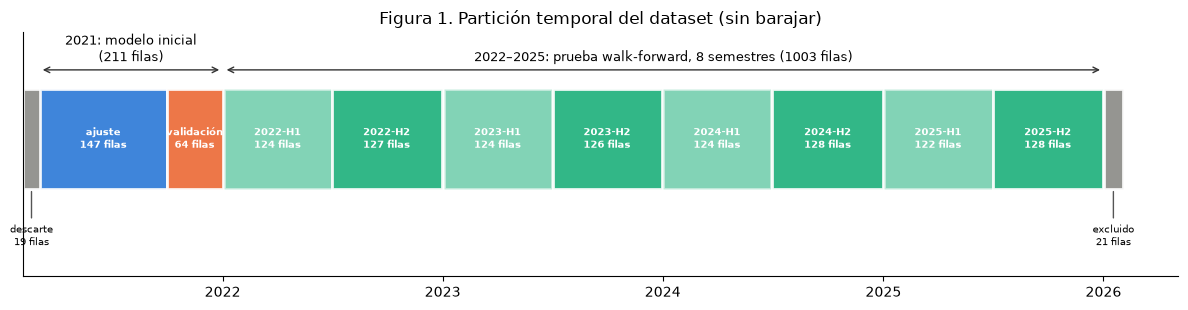

In [2]:
tramos = [("descarte", raw.date.iloc[0], ds.index[0], (raw.date < ds.index[0]).sum(), GRIS),
          ("ajuste", fit_df.index[0], fit_df.index[-1], len(fit_df), COLOR["A"]),
          ("validación", val_df.index[0], val_df.index[-1], len(val_df), COLOR["B"])]
tramos += [(w.window_id, w.start, w.end, w.n, COLOR["C"]) for w in windows]
tramos += [("excluido", tail.index[0], raw.date.iloc[-1], len(tail) + 1, GRIS)]
fig, ax = plt.subplots(figsize=(12, 3.2))
for i, (lab, a, b, n, c) in enumerate(tramos):
    alpha = 0.55 if lab.startswith("20") and i % 2 else 0.9
    ax.barh(0, (b - a).days + 1, left=a, color=c, alpha=alpha, edgecolor="white", linewidth=2)
    if n > 30:   # bloques anchos: rótulo dentro
        ax.text(a + (b - a) / 2, 0, f"{lab}\n{n} filas", ha="center", va="center", fontsize=7.5, color="white", fontweight="bold")
    else:        # bloques angostos: rótulo debajo
        ax.annotate(f"{lab}\n{n} filas", xy=(a + (b - a) / 2, -0.4), xytext=(a + (b - a) / 2, -0.85),
                    ha="center", fontsize=7.5, arrowprops=dict(arrowstyle="-", color="#555"))
for x0, x1, txt in [(fit_df.index[0], val_df.index[-1], "2021: modelo inicial\n(211 filas)"),
                    (windows[0].start, windows[-1].end, "2022–2025: prueba walk-forward, 8 semestres (1003 filas)")]:
    ax.annotate("", xy=(x0, 0.55), xytext=(x1, 0.55), arrowprops=dict(arrowstyle="<->", color="#333"))
    ax.text(x0 + (x1 - x0) / 2, 0.62, txt, ha="center", fontsize=9)
ax.set_yticks([]); ax.set_ylim(-1.1, 0.85); ax.grid(False); ax.set_title("Figura 1. Partición temporal del dataset (sin barajar)")
plt.tight_layout(); fig.savefig(FIG / "fig1_particion.png", dpi=200)

**Cómo leerlo:** cada bloque es un tramo de días bursátiles, en orden cronológico. El modelo solo aprende de bloques a la izquierda del que predice.

**Qué concluimos:** 2021 sirve para **construir** el modelo (ajuste → elegir hiperparámetros, validación → confirmar la elección). Las 8 ventanas semestrales son el **examen**: datos que el modelo nunca vio. Enero de 2026 queda fuera porque es un semestre incompleto.

## 4. Figura 2 — Qué hace cada grupo en cada ventana

Lo único que distingue a A, B y C es **cuándo** cambian de modelo. Cada barra muestra la versión del modelo vigente en esa ventana.

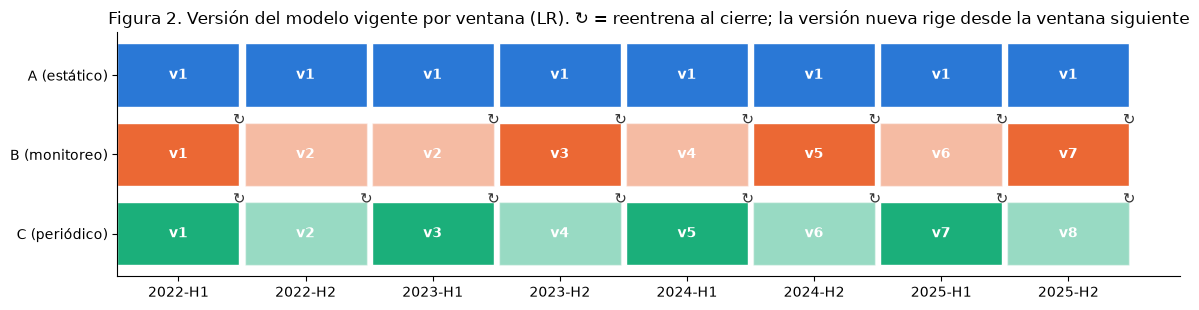

In [3]:
wm = pd.read_csv("results/window_metrics.csv")
ver = wm[(wm.replica == "logreg") & wm.group.isin(list("ABC"))].pivot(index="group", columns="window_id", values="version")
reason = wm[(wm.replica == "logreg") & wm.group.isin(list("ABC"))].pivot(index="group", columns="window_id", values="retrain_reason")
fig, ax = plt.subplots(figsize=(12, 3.2))
for row, g in enumerate(["C", "B", "A"]):
    for j, wid in enumerate(ver.columns):
        v = int(ver.loc[g, wid])
        ax.barh(row, 0.96, left=j, color=COLOR[g], alpha=0.45 + 0.55 * (v % 2), edgecolor="white")
        ax.text(j + 0.48, row, f"v{v}", ha="center", va="center", color="white", fontweight="bold")
        if isinstance(reason.loc[g, wid], str):
            ax.text(j + 0.96, row + 0.38, "↻", ha="center", fontsize=11, color="#333")
ax.set_yticks(range(3), ["C (periódico)", "B (monitoreo)", "A (estático)"]); ax.set_xticks(np.arange(8) + 0.48, ver.columns)
ax.grid(False); ax.set_title("Figura 2. Versión del modelo vigente por ventana (LR). ↻ = reentrena al cierre; la versión nueva rige desde la ventana siguiente")
plt.tight_layout(); fig.savefig(FIG / "fig2_versiones.png", dpi=200)

**Cómo leerlo:** las filas son los grupos y las columnas las ventanas. El número es la versión del modelo y el símbolo ↻ indica que al cierre de esa ventana se reentrenó.

**Qué concluimos:** **A** usa la versión 1 todo el tiempo. **C** cambia de versión en cada semestre. **B** solo debía cambiar ante una alarma, pero la alarma de deriva saltó en 7 de 8 ventanas, así que B terminó casi igual que C. La única diferencia es 2022-H2, donde B no reentrenó.

## 5. Figura 3 — Protocolo que se repite al cierre de cada ventana

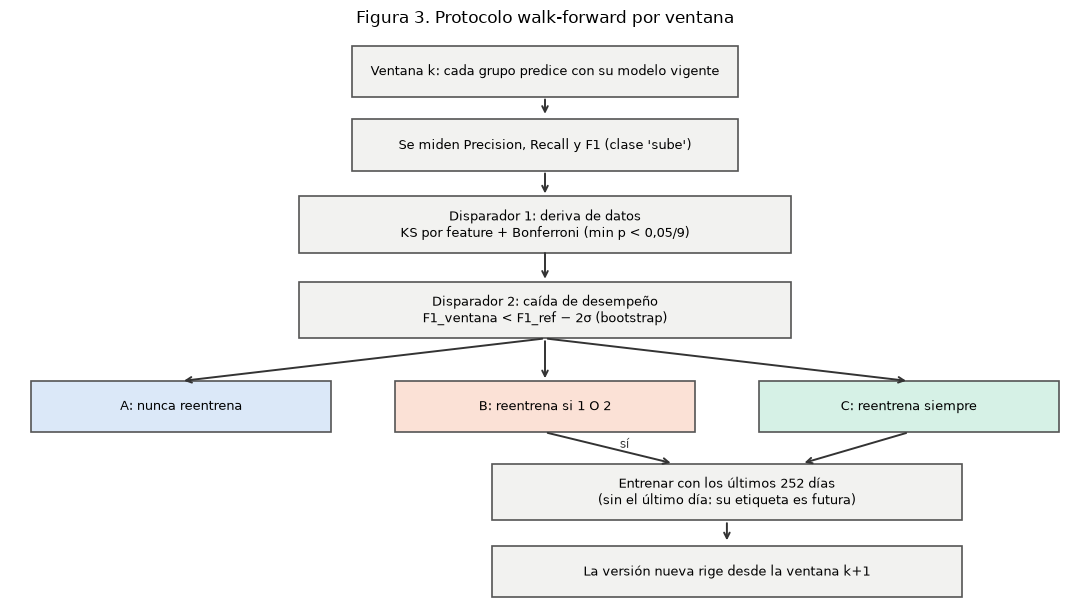

In [4]:
fig, ax = plt.subplots(figsize=(11, 6.2)); ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 10)
def caja(x, y, txt, c="#f2f2f0", w=3.6, h=0.9):
    ax.add_patch(plt.Rectangle((x - w / 2, y - h / 2), w, h, facecolor=c, edgecolor="#555", lw=1.2))
    ax.text(x, y, txt, ha="center", va="center", fontsize=9)
def flecha(x1, y1, x2, y2, txt=""):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color="#333", lw=1.4))
    if txt: ax.text((x1 + x2) / 2 + 0.1, (y1 + y2) / 2, txt, fontsize=8.5, color="#333")
caja(5, 9.3, "Ventana k: cada grupo predice con su modelo vigente")
caja(5, 8.0, "Se miden Precision, Recall y F1 (clase 'sube')")
caja(5, 6.6, "Disparador 1: deriva de datos\nKS por feature + Bonferroni (min p < 0,05/9)", w=4.6, h=1.0)
caja(5, 5.1, "Disparador 2: caída de desempeño\nF1_ventana < F1_ref − 2σ (bootstrap)", w=4.6, h=1.0)
caja(1.6, 3.4, "A: nunca reentrena", c="#dbe8f8", w=2.8)
caja(5, 3.4, "B: reentrena si 1 O 2", c="#fbe1d6", w=2.8)
caja(8.4, 3.4, "C: reentrena siempre", c="#d6f1e6", w=2.8)
caja(6.7, 1.9, "Entrenar con los últimos 252 días\n(sin el último día: su etiqueta es futura)", w=4.4, h=1.0)
caja(6.7, 0.5, "La versión nueva rige desde la ventana k+1", w=4.4)
for (a, b) in [(9.3, 8.0), (8.0, 6.6), (6.6, 5.1)]: flecha(5, a - 0.45, 5, b + 0.5)
flecha(5, 4.6, 1.6, 3.85); flecha(5, 4.6, 5, 3.85); flecha(5, 4.6, 8.4, 3.85)
flecha(5, 2.95, 6.2, 2.4, "sí"); flecha(8.4, 2.95, 7.4, 2.4); flecha(6.7, 1.4, 6.7, 1.0)
ax.set_title("Figura 3. Protocolo walk-forward por ventana")
plt.tight_layout(); fig.savefig(FIG / "fig3_protocolo.png", dpi=200)

**Cómo leerlo:** se lee de arriba hacia abajo. Las dos alarmas se calculan siempre, pero solo B las usa para decidir.

**Qué concluimos:** El protocolo garantiza **causalidad**: el modelo nunca ve la ventana que predice, y una versión nueva nunca se evalúa en la ventana que la originó. Los detalles de cada alarma están en el notebook 04.

## 6. Figura 4 — Ventana deslizante de reentrenamiento

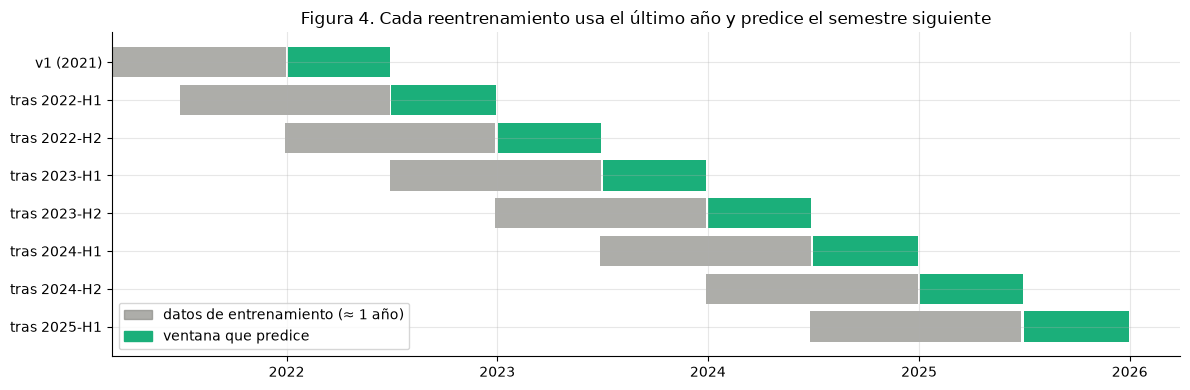

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.barh(0, (initial_df.index[-1] - initial_df.index[0]).days, left=initial_df.index[0], color=GRIS, alpha=0.7)
ax.barh(0, (windows[0].end - windows[0].start).days, left=windows[0].start, color=COLOR["C"])
for k, w in enumerate(windows[:-1], start=1):
    tr = last_year_training(ds, w, cfg["retrain"]["window_rows"]); nxt = windows[k]
    ax.barh(k, (tr.index[-1] - tr.index[0]).days, left=tr.index[0], color=GRIS, alpha=0.7)
    ax.barh(k, (nxt.end - nxt.start).days, left=nxt.start, color=COLOR["C"])
ax.set_yticks(range(len(windows)), ["v1 (2021)"] + [f"tras {w.window_id}" for w in windows[:-1]])
from matplotlib.patches import Patch
ax.invert_yaxis()
ax.legend(handles=[Patch(color=GRIS, alpha=0.7, label="datos de entrenamiento (≈ 1 año)"), Patch(color=COLOR["C"], label="ventana que predice")], loc="lower left"); ax.set_title("Figura 4. Cada reentrenamiento usa el último año y predice el semestre siguiente")
plt.tight_layout(); fig.savefig(FIG / "fig4_ventana_deslizante.png", dpi=200)

**Cómo leerlo:** cada fila es una versión del modelo. La barra gris muestra con qué datos se entrenó y la barra verde qué semestre predice después.

**Qué concluimos:** La ventana de entrenamiento **se desliza**: siempre es el último año y olvida lo anterior ([8], [11], decisión D6). Por eso un modelo entrenado tras el año bajista de 2022 aprende un mercado bajista. Esto es clave para entender los resultados (notebook 06).

## 7. Figura 5 — ¿Cómo se decide si una política gana? (Wilcoxon)

**Por qué Wilcoxon de rangos con signo pareado:**
- **Pareado:** las tres políticas se evalúan sobre las mismas 8 ventanas, así que se compara ventana contra ventana.
- **No paramétrico:** con 8 puntos no se puede suponer normalidad, y el F1 no es normal ([25]).

**Cómo funciona:** se ordenan las diferencias por tamaño y se suman los rangos de las positivas (W). Si H₀ es cierta, el signo de cada diferencia es como lanzar una moneda. Con n diferencias hay 2ⁿ combinaciones de signos igual de probables, y de ahí sale la distribución nula exacta.

Con n = 8 el p mínimo posible es 2/2^8 = 0.0078; con n = 7, 0.0156


,replica,comparison,wilcoxon_statistic,p_value
0,logreg,B-A,12.0,0.812
1,logreg,C-A,11.0,0.688
3,rf,B-A,13.0,0.938
4,rf,C-A,13.0,0.938


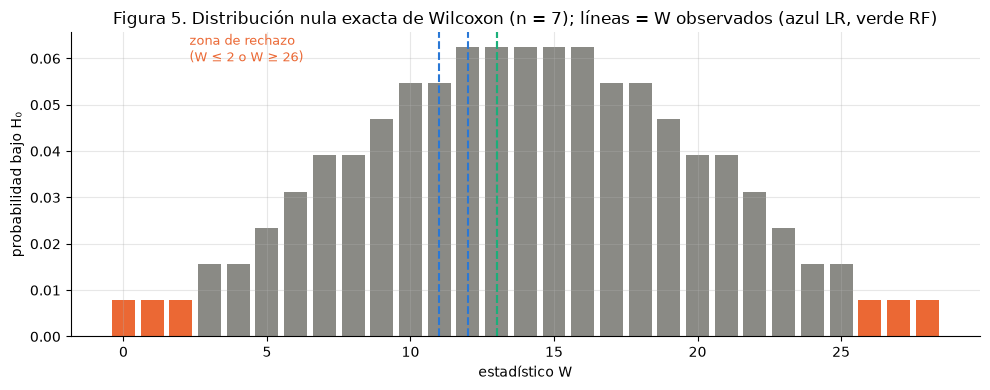

In [6]:
import itertools
cmp = pd.read_csv("results/comparisons.csv")
n = 7  # B−A y C−A tienen 1 empate de 8 → 7 diferencias no nulas
W = np.array([sum(r for r, s in zip(range(1, n + 1), sg) if s) for sg in itertools.product([0, 1], repeat=n)])
vals, cnt = np.unique(W, return_counts=True)
crit = max(w for w in vals if 2 * (W <= w).mean() <= 0.05)
fig, ax = plt.subplots()
ax.bar(vals, cnt / len(W), color=[COLOR["B"] if (v <= crit or v >= n * (n + 1) / 2 - crit) else GRIS for v in vals])
obs = cmp[cmp.comparison.isin(["B-A", "C-A"])]
for _, r in obs.iterrows():
    ax.axvline(r.wilcoxon_statistic, color=COLOR["A"] if r.replica == "logreg" else COLOR["C"], ls="--", lw=1.5)
ax.text(crit + 0.3, (cnt / len(W)).max() * 0.95, f"zona de rechazo\n(W ≤ {crit} o W ≥ {int(n*(n+1)/2-crit)})", color=COLOR["B"], fontsize=9)
ax.set_xlabel("estadístico W"); ax.set_ylabel("probabilidad bajo H₀")
ax.set_title(f"Figura 5. Distribución nula exacta de Wilcoxon (n = {n}); líneas = W observados (azul LR, verde RF)")
plt.tight_layout(); fig.savefig(FIG / "fig5_wilcoxon.png", dpi=200)
print(f"Con n = 8 el p mínimo posible es 2/2^8 = {2/2**8:.4f}; con n = 7, {2/2**7:.4f}")
obs[["replica", "comparison", "wilcoxon_statistic", "p_value"]]

**Cómo leerlo:** las barras son la probabilidad de cada valor de W si las políticas fueran iguales. Solo los extremos naranjas permitirían rechazar H₀ con 95 % de confianza. Las líneas punteadas son los W observados.

**Qué concluimos:** Los W observados (11–13) caen en el **centro** de la distribución: lo esperable si no hay diferencia. **No se rechaza H₀.** Ojo: con tan pocas ventanas solo se detectarían diferencias que se repitan casi en todas, así que "no significativo" **no** prueba que las políticas sean iguales (baja potencia).